# Automated Dental Plaque & Biofilm Segmentation from Clinical Photography
## Deep Learning Diagnostic Pipeline: Semantic Segmentation with ResNet-34 UNet
### High-Performance Computer Vision System: 40 Epochs Training with Best Model Checkpointing

---

### Clinical Context & Diagnostic Modality Distinction

- **Physical Modality:** Clinical Intraoral Color Photography (`Datasets/ODS_dataset/Plaques`).
- **Why Photography over Radiographs?** Dental plaque is an uncalcified, soft bacterial biofilm. On dental X-rays/radiographs, plaque has identical radiodensity to saliva and soft tissue, rendering it completely invisible. Detecting plaque biofilm requires high-resolution color intraoral photography capturing light reflection, bacterial pigmentation, and gingival margin accumulation.
- **Target Pathology:** Bacterial plaque biofilm accumulation on tooth enamel, interproximal spaces, and gingival margins.
- **AI Architecture:** ResNet-34 UNet trained with Color Jitter, spatial affine augmentations, Cosine Annealing learning rate schedule, and Compound (BCE + Soft Dice) Loss across **40 Epochs**.
- **Production Artifact:** Automatically checkpoints and exports the optimal validation checkpoint to `models/plaque_unet.pth`.

---

### Pipeline Structure
1. **Section 1: Environment Setup, Dependencies & Hardware Acceleration**
2. **Section 2: Photographic Data Ingestion & Exact Mask Parsing** (`lbl_bgr[:, :, 2] > 0`)
3. **Section 3: Exploratory Data Analysis (EDA) & Plaque Distribution Profiling**
4. **Section 4: Color-Preserving Preprocessing, Data Augmentation & High-Speed RAM Caching**
5. **Section 5: Plaque UNet Model Architecture & Compound Loss Formulation**
6. **Section 6: Plaque UNet 40-Epoch Training Pipeline & Best Epoch Selection** (`models/plaque_unet.pth`)
7. **Section 7: Comprehensive Test Set Evaluation, Metric Threshold Sweep & ROC/PR Curves**
8. **Section 8: Qualitative Diagnostic Overlays on Clinical Test Cases** (Clean vs Mild vs Confluent)
9. **Section 9: Production Model Verification for Deployment & Streamlit App**


In [1]:
# ==============================================================================
# SECTION 1: Environment Setup, Dependencies & Hardware Acceleration
# ==============================================================================

import os
import sys
import time
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp
from sklearn.metrics import roc_curve, auc, precision_recall_curve

# Configure Matplotlib styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# Reproducibility seed
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"[*] PyTorch Version: {torch.__version__}")
print(f"[*] Active Hardware Device: {device}")
if torch.cuda.is_available():
    print(f"[*] GPU Device Name: {torch.cuda.get_device_name(0)}")
    print(f"[*] CUDA Capability: {torch.cuda.get_device_capability(0)}")
    print(f"[*] Total Dedicated VRAM: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")

# Project Directory Structure
NOTEBOOK_DIR = Path.cwd()
ROOT_DIR = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name.lower() == 'notebooks' else NOTEBOOK_DIR
DATASETS_DIR = ROOT_DIR / "Datasets"
MODELS_DIR = ROOT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

ODS_DIR = DATASETS_DIR / "ODS_dataset"
PLAQUE_IMG_DIR = ODS_DIR / "Plaques" / "img"
PLAQUE_LBL_DIR = ODS_DIR / "Plaques" / "label"
PLAQUE_MODEL_PATH = MODELS_DIR / "plaque_unet.pth"

print(f"[*] Root Workspace: {ROOT_DIR}")
print(f"[*] Plaque Images Directory: {PLAQUE_IMG_DIR.exists()} ({PLAQUE_IMG_DIR})")
print(f"[*] Plaque Labels Directory: {PLAQUE_LBL_DIR.exists()} ({PLAQUE_LBL_DIR})")
print(f"[*] Target Export Checkpoint: {PLAQUE_MODEL_PATH}")


[*] PyTorch Version: 2.14.1+cu130
[*] Active Hardware Device: cuda
[*] GPU Device Name: NVIDIA GeForce RTX 5060 Laptop GPU
[*] CUDA Capability: (12, 0)
[*] Total Dedicated VRAM: 7.93 GB
[*] Root Workspace: d:\GItRepo\Automated Dental Caries and Plaque Detection from Intraoral Radiographs
[*] Plaque Images Directory: True (d:\GItRepo\Automated Dental Caries and Plaque Detection from Intraoral Radiographs\Datasets\ODS_dataset\Plaques\img)
[*] Plaque Labels Directory: True (d:\GItRepo\Automated Dental Caries and Plaque Detection from Intraoral Radiographs\Datasets\ODS_dataset\Plaques\label)
[*] Target Export Checkpoint: d:\GItRepo\Automated Dental Caries and Plaque Detection from Intraoral Radiographs\models\plaque_unet.pth


---
## Section 2: Photographic Data Ingestion & Ground Truth Mask Parsing

In `Datasets/ODS_dataset/Plaques`, each clinical photography image (`img/*.png`) corresponds to a label mask (`label/*.png`).

### Key Annotation Protocol:
The ground truth annotations store the plaque biofilm pixel delineations inside the **Red channel (Channel 2 in OpenCV BGR)**:
- **Sound tooth enamel / Background:** Pixel value = $0$
- **Plaque Biofilm:** Pixel value $> 0$ (values up to $128$)

Hence, the binary ground truth mask is extracted as `(lbl_bgr[:, :, 2] > 0).astype(np.uint8)`.


In [2]:
# ==============================================================================
# SECTION 2: Photographic Data Ingestion & Train/Val/Test Partitioning
# ==============================================================================

plaque_img_files = sorted(list(PLAQUE_IMG_DIR.glob("*.png")))
plaque_pairs = []
for p in plaque_img_files:
    lbl_p = PLAQUE_LBL_DIR / f"{p.stem}.png"
    if lbl_p.exists():
        plaque_pairs.append((str(p), str(lbl_p)))

print(f"[*] Total verified Plaque photographic pairs: {len(plaque_pairs)}")

# Train / Val / Test Split (70% Train, 15% Validation, 15% Test)
np.random.seed(SEED)
np.random.shuffle(plaque_pairs)
n_plaque_tot = len(plaque_pairs)
n_p_tr = int(n_plaque_tot * 0.70)
n_p_val = int(n_plaque_tot * 0.15)

plaque_train_pairs = plaque_pairs[:n_p_tr]
plaque_val_pairs = plaque_pairs[n_p_tr:n_p_tr + n_p_val]
plaque_test_pairs = plaque_pairs[n_p_tr + n_p_val:]

print(f"[*] Plaque Cohort Split:")
print(f"    - Training Set   : {len(plaque_train_pairs)} pairs ({len(plaque_train_pairs)/n_plaque_tot*100:.1f}%)")
print(f"    - Validation Set : {len(plaque_val_pairs)} pairs ({len(plaque_val_pairs)/n_plaque_tot*100:.1f}%)")
print(f"    - Test Set       : {len(plaque_test_pairs)} pairs ({len(plaque_test_pairs)/n_plaque_tot*100:.1f}%)")


[*] Total verified Plaque photographic pairs: 1293
[*] Plaque Cohort Split:
    - Training Set   : 905 pairs (70.0%)
    - Validation Set : 193 pairs (14.9%)
    - Test Set       : 195 pairs (15.1%)


---
## Section 3: Exploratory Data Analysis (EDA) & Plaque Distribution Profiling

Before model training, we perform an in-depth clinical EDA to analyze:
1. Image resolutions, aspect ratios, and color distributions across the cohort.
2. Ground truth plaque biofilm coverage percentages per image.
3. Prevalence of clean teeth (zero plaque) versus mild and confluent biofilm deposits.
4. Visual overlay of representative photographic cases across clinical severity categories.


[*] Computing dataset statistics on photographic images and plaque masks...


Analyzing sample cohort:   0%|          | 0/300 [00:00<?, ?it/s]


[*] Plaque EDA Summary Statistics:
       coverage_pct  plaque_px
count        300.00     300.00
mean           8.84   23131.84
std           13.17   34458.76
min            0.00       0.00
25%            0.00       0.00
50%            2.89    7573.00
75%           13.48   35226.25
max           65.73  171640.00
[*] Biofilm Positive Prevalence in Sample: 185/300 (61.7%)


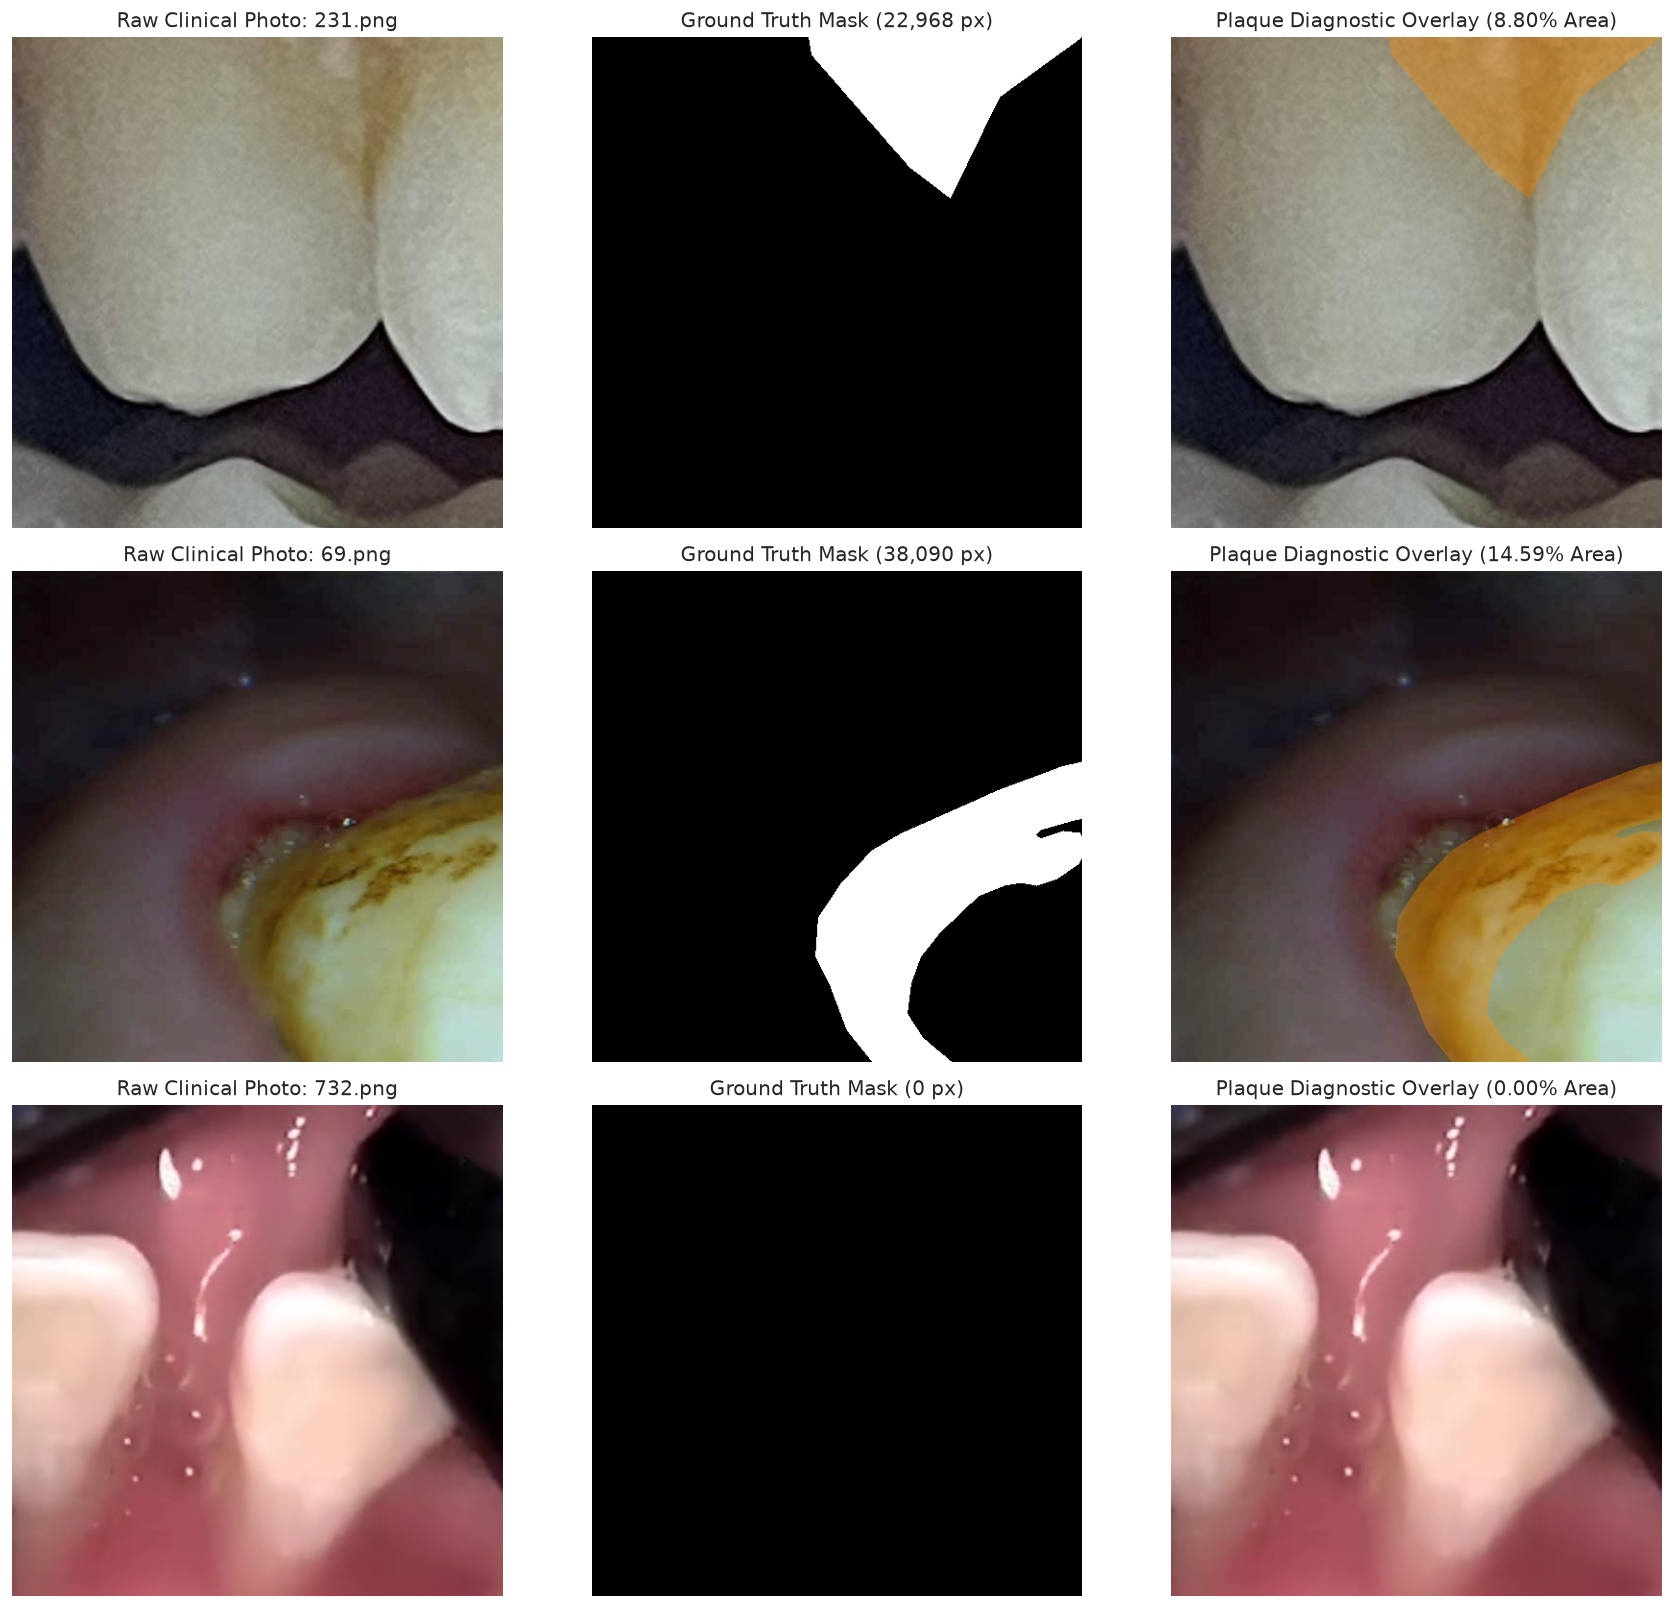

In [3]:
# ==============================================================================
# SECTION 3: Exploratory Data Analysis (EDA)
# ==============================================================================

eda_records = []
print("[*] Computing dataset statistics on photographic images and plaque masks...")

for img_p, lbl_p in tqdm(plaque_pairs[:300], desc="Analyzing sample cohort"):  # Profile representative sample
    bgr = cv2.imread(img_p)
    h, w, c = bgr.shape
    lbl_bgr = cv2.imread(lbl_p)
    mask = (lbl_bgr[:, :, 2] > 0).astype(np.uint8)
    plaque_px = np.sum(mask)
    coverage_pct = (plaque_px / (h * w)) * 100.0
    eda_records.append({
        'height': h, 'width': w,
        'plaque_px': plaque_px,
        'coverage_pct': coverage_pct,
        'has_plaque': plaque_px > 0
    })

df_eda = pd.DataFrame(eda_records)
print("\n[*] Plaque EDA Summary Statistics:")
print(df_eda[['coverage_pct', 'plaque_px']].describe().round(2))
pos_count = df_eda['has_plaque'].sum()
print(f"[*] Biofilm Positive Prevalence in Sample: {pos_count}/{len(df_eda)} ({pos_count/len(df_eda)*100:.1f}%)")

# Visual Exploration across Clinical Severity Tiers
sample_indices = [0, 5, 20]
fig, axes = plt.subplots(len(sample_indices), 3, figsize=(15, 4.5 * len(sample_indices)))

for i, s_idx in enumerate(sample_indices):
    img_p, lbl_p = plaque_train_pairs[s_idx]
    bgr = cv2.imread(img_p)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    lbl_bgr = cv2.imread(lbl_p)
    mask = (lbl_bgr[:, :, 2] > 0).astype(np.uint8)
    cov = (np.sum(mask) / (mask.shape[0] * mask.shape[1])) * 100.0
    
    axes[i, 0].imshow(rgb)
    axes[i, 0].set_title(f"Raw Clinical Photo: {Path(img_p).name}")
    axes[i, 0].axis('off')
    
    axes[i, 1].imshow(mask, cmap='gray')
    axes[i, 1].set_title(f"Ground Truth Mask ({np.sum(mask):,} px)")
    axes[i, 1].axis('off')
    
    overlay = rgb.copy()
    overlay[mask == 1] = [255, 140, 0]  # Amber/Orange for plaque biofilm
    axes[i, 2].imshow(cv2.addWeighted(rgb, 0.65, overlay, 0.35, 0))
    axes[i, 2].set_title(f"Plaque Diagnostic Overlay ({cov:.2f}% Area)")
    axes[i, 2].axis('off')

plt.tight_layout()
plt.show()


---
## Section 4: Color-Preserving Preprocessing, Data Augmentation & High-Speed RAM Caching

### Preprocessing Strategy:
1. **Uniform $512 \times 512$ Standard Spatial Scale:** Bilinear interpolation for clinical RGB photos, nearest-neighbor for ground truth masks to preserve crisp binary boundaries.
2. **RAM Pre-Caching:** Pre-loading and resizing the entire photographic dataset into RAM completely eliminates disk I/O bottlenecks during 40 epochs of training.
3. **Color-Aware Augmentations (`albumentations`):**
   - Horizontal flipping ($p=0.5$)
   - Subtle spatial affine scaling & slight rotation ($\pm 10^{\circ}$)
   - Controlled `ColorJitter` (brightness, contrast, saturation) to simulate camera white-balance and flash variations without shifting hue into artificial spectra.
   - Standard ImageNet normalization: $\mu = [0.485, 0.456, 0.406]$, $\sigma = [0.229, 0.224, 0.225]$.


In [4]:
# ==============================================================================
# SECTION 4: Fast RAM Caching & PyTorch Dataset Pipeline
# ==============================================================================

print("[*] Pre-caching resized 512x512 photographic images and masks into RAM...")
t_p_cache = time.time()

def load_plaque_sample(pair):
    img_p, lbl_p = pair
    bgr = cv2.imread(img_p)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    rgb_512 = cv2.resize(rgb, (512, 512), interpolation=cv2.INTER_LINEAR)
    lbl_bgr = cv2.imread(lbl_p)
    mask = (lbl_bgr[:, :, 2] > 0).astype(np.uint8)
    mask_512 = cv2.resize(mask, (512, 512), interpolation=cv2.INTER_NEAREST)
    return rgb_512, mask_512

plaque_train_cached = [load_plaque_sample(p) for p in plaque_train_pairs]
plaque_val_cached = [load_plaque_sample(p) for p in plaque_val_pairs]
plaque_test_cached = [load_plaque_sample(p) for p in plaque_test_pairs]

print(f"[*] Cached {len(plaque_pairs)} photographic pairs into RAM in {time.time() - t_p_cache:.2f}s.")

p_tr_pos = sum(1 for _, m in plaque_train_cached if np.sum(m) > 0)
p_val_pos = sum(1 for _, m in plaque_val_cached if np.sum(m) > 0)
p_test_pos = sum(1 for _, m in plaque_test_cached if np.sum(m) > 0)
print(f"[*] Plaque Positive Cases - Train: {p_tr_pos}/{len(plaque_train_cached)} ({p_tr_pos/len(plaque_train_cached)*100:.1f}%), "
      f"Val: {p_val_pos}/{len(plaque_val_cached)} ({p_val_pos/len(plaque_val_cached)*100:.1f}%)")

class CachedPlaqueDataset(Dataset):
    def __init__(self, data, transform=None):
        self.data = data
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        rgb, mask = self.data[idx]
        if self.transform:
            aug = self.transform(image=rgb, mask=mask)
            img = aug['image']
            mask = aug['mask']
        else:
            img = rgb.astype(np.float32) / 255.0
            mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
            std = np.array([0.229, 0.224, 0.225], dtype=np.float32)
            img = (img - mean) / std
            img = torch.tensor(img).permute(2, 0, 1).float()
            mask = torch.tensor(mask).float()

        if mask.dim() == 2:
            mask = mask.unsqueeze(0).float()
        else:
            mask = mask.float()
        return img, mask

plaque_train_tf = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Affine(scale=(0.95, 1.05), rotate=(-10, 10), border_mode=cv2.BORDER_CONSTANT, p=0.5),
    A.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, p=0.5),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

plaque_val_tf = A.Compose([
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

plaque_train_ds = CachedPlaqueDataset(plaque_train_cached, transform=plaque_train_tf)
plaque_val_ds = CachedPlaqueDataset(plaque_val_cached, transform=plaque_val_tf)
plaque_test_ds = CachedPlaqueDataset(plaque_test_cached, transform=plaque_val_tf)

plaque_train_loader = DataLoader(plaque_train_ds, batch_size=16, shuffle=True, pin_memory=True)
plaque_val_loader = DataLoader(plaque_val_ds, batch_size=16, shuffle=False, pin_memory=True)
plaque_test_loader = DataLoader(plaque_test_ds, batch_size=16, shuffle=False, pin_memory=True)

print(f"[*] DataLoaders Ready: {len(plaque_train_loader)} train batches, {len(plaque_val_loader)} val batches.")


[*] Pre-caching resized 512x512 photographic images and masks into RAM...
[*] Cached 1293 photographic pairs into RAM in 9.76s.
[*] Plaque Positive Cases - Train: 506/905 (55.9%), Val: 109/193 (56.5%)
[*] DataLoaders Ready: 57 train batches, 13 val batches.


---
## Section 5: Plaque UNet Architecture & Plaque Compound Loss Formulation

### Neural Architecture:
- **Backbone:** ResNet-34 pretrained on ImageNet for high-fidelity multi-scale feature representation.
- **Decoder:** Symmetric UNet decoder with skip-connections and transpose convolutions.
- **In/Out Channels:** 3 color input channels (RGB), 1 single-class output logit mask (plaque biofilm).

### Loss Function Formulation:
$$\mathcal{L}_{\text{compound}} = 0.5 \cdot \mathcal{L}_{\text{BCE}} + 0.5 \cdot \mathcal{L}_{\text{Dice}}$$
$$\mathcal{L}_{\text{Dice}} = 1 - \frac{2 \sum (p_i \cdot t_i) + \epsilon}{\sum p_i + \sum t_i + \epsilon}$$
This compound formulation ensures smooth pixel-level gradient stability (BCE) while directly optimizing region-level spatial overlap (Dice).


In [5]:
# ==============================================================================
# SECTION 5: Dedicated Plaque UNet Architecture & Loss Formulation
# ==============================================================================

class SoftDiceLoss(nn.Module):
    def __init__(self, smooth=1e-5):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits).view(-1)
        targets_f = targets.view(-1)
        intersection = (probs * targets_f).sum()
        dice = (2.0 * intersection + self.smooth) / (probs.sum() + targets_f.sum() + self.smooth)
        return 1.0 - dice

class PlaqueCompoundLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = SoftDiceLoss()

    def forward(self, logits, targets):
        return 0.5 * self.bce(logits, targets) + 0.5 * self.dice(logits, targets)

plaque_model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
).to(device)

plaque_criterion = PlaqueCompoundLoss()
plaque_optimizer = optim.AdamW(plaque_model.parameters(), lr=3e-4, weight_decay=1e-4)

PLAQUE_EPOCHS = 40
plaque_scheduler = optim.lr_scheduler.CosineAnnealingLR(plaque_optimizer, T_max=PLAQUE_EPOCHS, eta_min=1e-6)
plaque_scaler = torch.amp.GradScaler('cuda') if torch.cuda.is_available() else None

print(f"[*] Dedicated Plaque UNet Initialized.")
print(f"[*] Training Budget: {PLAQUE_EPOCHS} Epochs with Cosine Annealing Learning Rate Schedule.")
print(f"[*] Target Export Checkpoint: {PLAQUE_MODEL_PATH}")


[*] Dedicated Plaque UNet Initialized.
[*] Training Budget: 40 Epochs with Cosine Annealing Learning Rate Schedule.
[*] Target Export Checkpoint: d:\GItRepo\Automated Dental Caries and Plaque Detection from Intraoral Radiographs\models\plaque_unet.pth


---
## Section 6: Plaque UNet 40-Epoch Training Pipeline & Best Epoch Selection

Executes **40 Epochs** of mixed-precision training.
- After each epoch, validation loss, validation Dice (DSC), and sensitivity are recorded.
- When validation Dice improves upon the historical peak, the weights are automatically saved to `models/plaque_unet.pth`.
- Learning rate follows a cosine annealing curve down to $10^{-6}$ for fine-grained convergence.


[*] Starting Plaque UNet Training for 40 epochs on cuda...
Plaque Epoch [01/40] (30.3s) | Train Loss: 0.6542 | Val Loss: 0.6188 | Val Dice: 0.3424 | Sens: 0.9595 [NEW BEST -> plaque_unet.pth]
Plaque Epoch [02/40] (25.1s) | Train Loss: 0.5152 | Val Loss: 0.4890 | Val Dice: 0.5033 | Sens: 0.7454 [NEW BEST -> plaque_unet.pth]
Plaque Epoch [03/40] (24.9s) | Train Loss: 0.4333 | Val Loss: 0.3671 | Val Dice: 0.6259 | Sens: 0.8239 [NEW BEST -> plaque_unet.pth]
Plaque Epoch [05/40] (25.1s) | Train Loss: 0.3639 | Val Loss: 0.3263 | Val Dice: 0.6316 | Sens: 0.5546 [NEW BEST -> plaque_unet.pth]
Plaque Epoch [06/40] (25.2s) | Train Loss: 0.3459 | Val Loss: 0.3467 | Val Dice: 0.6363 | Sens: 0.8103 [NEW BEST -> plaque_unet.pth]
Plaque Epoch [07/40] (25.1s) | Train Loss: 0.3343 | Val Loss: 0.2646 | Val Dice: 0.7048 | Sens: 0.7908 [NEW BEST -> plaque_unet.pth]
Plaque Epoch [08/40] (25.1s) | Train Loss: 0.3246 | Val Loss: 0.2622 | Val Dice: 0.7151 | Sens: 0.7764 [NEW BEST -> plaque_unet.pth]
Plaque Epo

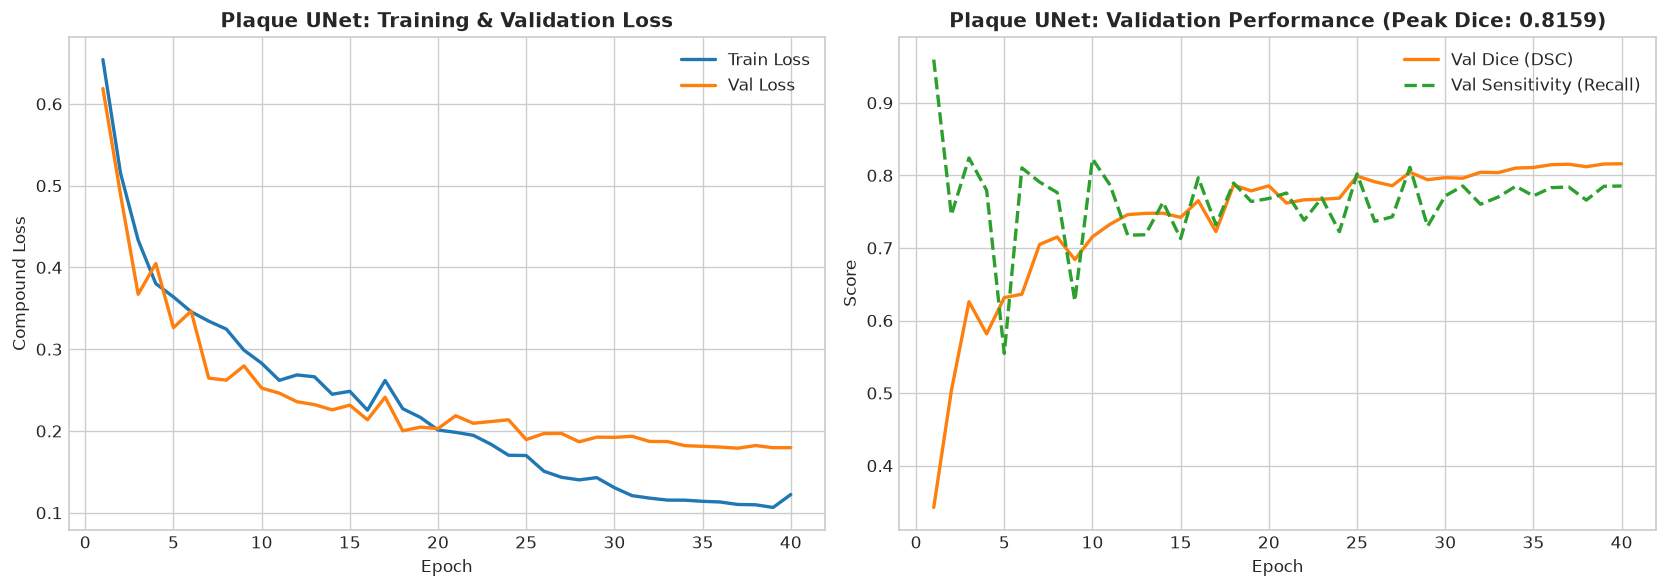

In [6]:
# ==============================================================================
# SECTION 6: Plaque UNet 40-Epoch Training Pipeline
# ==============================================================================

plaque_best_dice = 0.0
plaque_best_epoch = 0
plaque_history = {'train_loss': [], 'val_loss': [], 'val_dice': [], 'val_sens': []}

print(f"[*] Starting Plaque UNet Training for {PLAQUE_EPOCHS} epochs on {device}...")
p_start = time.time()

for epoch in range(1, PLAQUE_EPOCHS + 1):
    ep_t0 = time.time()
    plaque_model.train()
    running_loss = 0.0

    for imgs, msks in plaque_train_loader:
        imgs = imgs.to(device)
        msks = msks.to(device)
        plaque_optimizer.zero_grad()
        if plaque_scaler is not None:
            with torch.amp.autocast('cuda'):
                out = plaque_model(imgs)
                loss = plaque_criterion(out, msks)
            plaque_scaler.scale(loss).backward()
            plaque_scaler.step(plaque_optimizer)
            plaque_scaler.update()
        else:
            out = plaque_model(imgs)
            loss = plaque_criterion(out, msks)
            loss.backward()
            plaque_optimizer.step()
        running_loss += loss.item()

    plaque_scheduler.step()

    # Validation Loop
    plaque_model.eval()
    val_loss = 0.0
    val_tp, val_fp, val_fn = 0.0, 0.0, 0.0
    with torch.no_grad():
        for imgs, msks in plaque_val_loader:
            imgs = imgs.to(device)
            msks = msks.to(device)
            if plaque_scaler is not None:
                with torch.amp.autocast('cuda'):
                    out = plaque_model(imgs)
                    loss = plaque_criterion(out, msks)
            else:
                out = plaque_model(imgs)
                loss = plaque_criterion(out, msks)
            val_loss += loss.item()

            probs = torch.sigmoid(out)
            preds = (probs >= 0.40).float()
            val_tp += (preds * msks).sum().item()
            val_fp += (preds * (1 - msks)).sum().item()
            val_fn += ((1 - preds) * msks).sum().item()

    eps = 1e-6
    val_dice = (2 * val_tp + eps) / (2 * val_tp + val_fp + val_fn + eps)
    val_sens = (val_tp + eps) / (val_tp + val_fn + eps)
    dur = time.time() - ep_t0

    plaque_history['train_loss'].append(running_loss / len(plaque_train_loader))
    plaque_history['val_loss'].append(val_loss / len(plaque_val_loader))
    plaque_history['val_dice'].append(val_dice)
    plaque_history['val_sens'].append(val_sens)

    is_best = val_dice > plaque_best_dice
    if is_best:
        plaque_best_dice = val_dice
        plaque_best_epoch = epoch
        torch.save(plaque_model.state_dict(), PLAQUE_MODEL_PATH)

    if epoch % 5 == 0 or epoch == 1 or is_best:
        marker = f" [NEW BEST -> {PLAQUE_MODEL_PATH.name}]" if is_best else ""
        print(f"Plaque Epoch [{epoch:02d}/{PLAQUE_EPOCHS:02d}] ({dur:.1f}s) | Train Loss: {plaque_history['train_loss'][-1]:.4f} | "
              f"Val Loss: {plaque_history['val_loss'][-1]:.4f} | Val Dice: {val_dice:.4f} | Sens: {val_sens:.4f}{marker}")

print(f"\n[*] Plaque training complete in {(time.time() - p_start)/60:.2f} mins.")
print(f"[*] Peak Validation Dice: {plaque_best_dice:.4f} achieved at Epoch {plaque_best_epoch}.")
print(f"[*] Best checkpoint saved at: {PLAQUE_MODEL_PATH}")

# Plot Plaque Training Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(range(1, PLAQUE_EPOCHS + 1), plaque_history['train_loss'], label='Train Loss', color='#1f77b4', lw=2)
ax1.plot(range(1, PLAQUE_EPOCHS + 1), plaque_history['val_loss'], label='Val Loss', color='#ff7f0e', lw=2)
ax1.set_title('Plaque UNet: Training & Validation Loss', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Compound Loss')
ax1.legend()

ax2.plot(range(1, PLAQUE_EPOCHS + 1), plaque_history['val_dice'], label='Val Dice (DSC)', color='#ff7f0e', lw=2)
ax2.plot(range(1, PLAQUE_EPOCHS + 1), plaque_history['val_sens'], label='Val Sensitivity (Recall)', color='#2ca02c', lw=2, linestyle='--')
ax2.set_title(f'Plaque UNet: Validation Performance (Peak Dice: {plaque_best_dice:.4f})', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Score')
ax2.legend()
plt.tight_layout()
plt.show()


---
## Section 7: Comprehensive Test Set Evaluation, Metric Threshold Sweep & ROC/PR Curves

We evaluate `models/plaque_unet.pth` on the unseen test set across a full confidence threshold sweep (0.20 to 0.80):
- **Metrics:** Dice Similarity Coefficient (DSC), Sensitivity (Recall), Specificity, Precision, and Intersection-over-Union (IoU).
- **Post-Processing Filter:** Morphological connected-component noise filtering removes specks $< 40$ pixels.
- **Curves:** Receiver Operating Characteristic (ROC-AUC) and Precision-Recall (PR-AUC) on pixel predictions.


[*] Loaded best checkpoint from d:\GItRepo\Automated Dental Caries and Plaque Detection from Intraoral Radiographs\models\plaque_unet.pth


Evaluating Plaque Test Set:   0%|          | 0/13 [00:00<?, ?it/s]


[*] Plaque Test Diagnostic Performance across Threshold Sweep:
 Threshold  Dice (DSC)  Sensitivity  Specificity  Precision    IoU
      0.20      0.8364       0.8678       0.9819     0.8071 0.7188
      0.30      0.8388       0.8581       0.9836     0.8205 0.7224
      0.35      0.8394       0.8542       0.9842     0.8251 0.7233
      0.40      0.8399       0.8508       0.9847     0.8293 0.7240
      0.45      0.8400       0.8470       0.9852     0.8332 0.7242
      0.50      0.8402       0.8435       0.9857     0.8369 0.7244
      0.55      0.8405       0.8398       0.9862     0.8411 0.7249
      0.60      0.8405       0.8357       0.9867     0.8454 0.7249
      0.70      0.8394       0.8244       0.9878     0.8550 0.7233
      0.80      0.8361       0.8078       0.9891     0.8664 0.7183


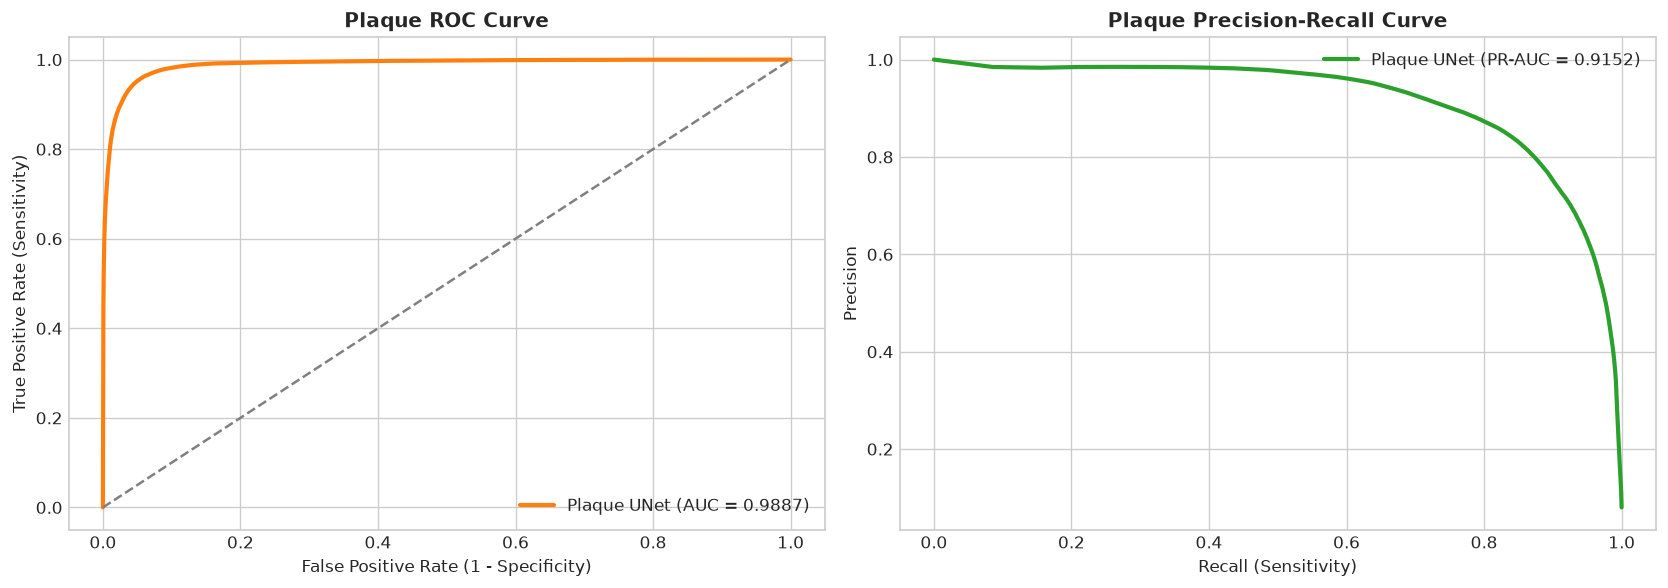

In [ ]:
# ==============================================================================
# SECTION 7: Plaque Test Set Evaluation, ROC Curve & PR Curve
# ==============================================================================

if PLAQUE_MODEL_PATH.exists():
    plaque_model.load_state_dict(torch.load(PLAQUE_MODEL_PATH, map_location=device))
    print(f"[*] Loaded best checkpoint from {PLAQUE_MODEL_PATH}")
plaque_model.eval()

plaque_test_probs = []
plaque_test_targets = []

with torch.no_grad():
    for imgs, msks in tqdm(plaque_test_loader, desc="Evaluating Plaque Test Set"):
        imgs = imgs.to(device)
        if plaque_scaler is not None:
            with torch.amp.autocast('cuda'):
                out = plaque_model(imgs)
        else:
            out = plaque_model(imgs)
        probs = torch.sigmoid(out)
        plaque_test_probs.append(probs.cpu().numpy())
        plaque_test_targets.append(msks.numpy())

plaque_test_probs = np.concatenate(plaque_test_probs, axis=0)
plaque_test_targets = np.concatenate(plaque_test_targets, axis=0)

plaque_thresholds = [0.20, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.70, 0.80]
p_sweep_rows = []

for th in plaque_thresholds:
    tp_tot, fp_tot, fn_tot, tn_tot = 0, 0, 0, 0
    for i in range(len(plaque_test_probs)):
        p = (plaque_test_probs[i, 0] >= th).astype(np.uint8)
        cnts, _ = cv2.findContours(p, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        clean_p = np.zeros_like(p)
        for c in cnts:
            if cv2.contourArea(c) >= 40:
                cv2.drawContours(clean_p, [c], -1, 1, thickness=-1)
        
        t = plaque_test_targets[i, 0].astype(np.uint8)
        tp_tot += np.sum((clean_p == 1) & (t == 1))
        fp_tot += np.sum((clean_p == 1) & (t == 0))
        fn_tot += np.sum((clean_p == 0) & (t == 1))
        tn_tot += np.sum((clean_p == 0) & (t == 0))
        
    eps = 1e-6
    d = (2 * tp_tot + eps) / (2 * tp_tot + fp_tot + fn_tot + eps)
    s = (tp_tot + eps) / (tp_tot + fn_tot + eps)
    prec = (tp_tot + eps) / (tp_tot + fp_tot + eps)
    spec = (tn_tot + eps) / (tn_tot + fp_tot + eps)
    iou = tp_tot / (tp_tot + fp_tot + fn_tot + eps)
    
    p_sweep_rows.append({
        'Threshold': th,
        'Dice (DSC)': round(d, 4),
        'Sensitivity': round(s, 4),
        'Specificity': round(spec, 4),
        'Precision': round(prec, 4),
        'IoU': round(iou, 4)
    })

df_plaque_metrics = pd.DataFrame(p_sweep_rows)
print("\n[*] Plaque Test Diagnostic Performance across Threshold Sweep:")
print(df_plaque_metrics.to_string(index=False))

# Compute ROC and PR Curves on subsampled test pixels
p_flat_probs = plaque_test_probs.flatten()[::10]
p_flat_targets = plaque_test_targets.flatten()[::10].astype(np.uint8)

p_fpr, p_tpr, _ = roc_curve(p_flat_targets, p_flat_probs)
p_roc_auc = auc(p_fpr, p_tpr)

p_precisions, p_recalls, _ = precision_recall_curve(p_flat_targets, p_flat_probs)
p_pr_auc = auc(p_recalls, p_precisions)

fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(14, 5))
ax_roc.plot(p_fpr, p_tpr, color='#ff7f0e', lw=2.5, label=f'Plaque UNet (AUC = {p_roc_auc:.4f})')
ax_roc.plot([0, 1], [0, 1], color='gray', linestyle='--')
ax_roc.set_title('Plaque ROC Curve', fontsize=12, fontweight='bold')
ax_roc.set_xlabel('False Positive Rate (1 - Specificity)')
ax_roc.set_ylabel('True Positive Rate (Sensitivity)')
ax_roc.legend(loc='lower right')
ax_roc.grid(True)

ax_pr.plot(p_recalls, p_precisions, color='#2ca02c', lw=2.5, label=f'Plaque UNet (PR-AUC = {p_pr_auc:.4f})')
ax_pr.set_title('Plaque Precision-Recall Curve', fontsize=12, fontweight='bold')
ax_pr.set_xlabel('Recall (Sensitivity)')
ax_pr.set_ylabel('Precision')
ax_pr.legend(loc='upper right')
ax_pr.grid(True)
plt.tight_layout()
plt.show()


---
## Section 8: Qualitative Diagnostic Overlays on Clinical Test Cases

Visual inspection across clinical scenarios:
1. **Clean Tooth Enamel (Zero Biofilm):** Confirming high specificity and zero false alarms on healthy teeth.
2. **Mild - Moderate Plaque Biofilm:** Accumulation near the gingival boundary and interproximal regions.
3. **Heavy Confluent Biofilm:** Extensive plaque coverage across multiple tooth crowns.


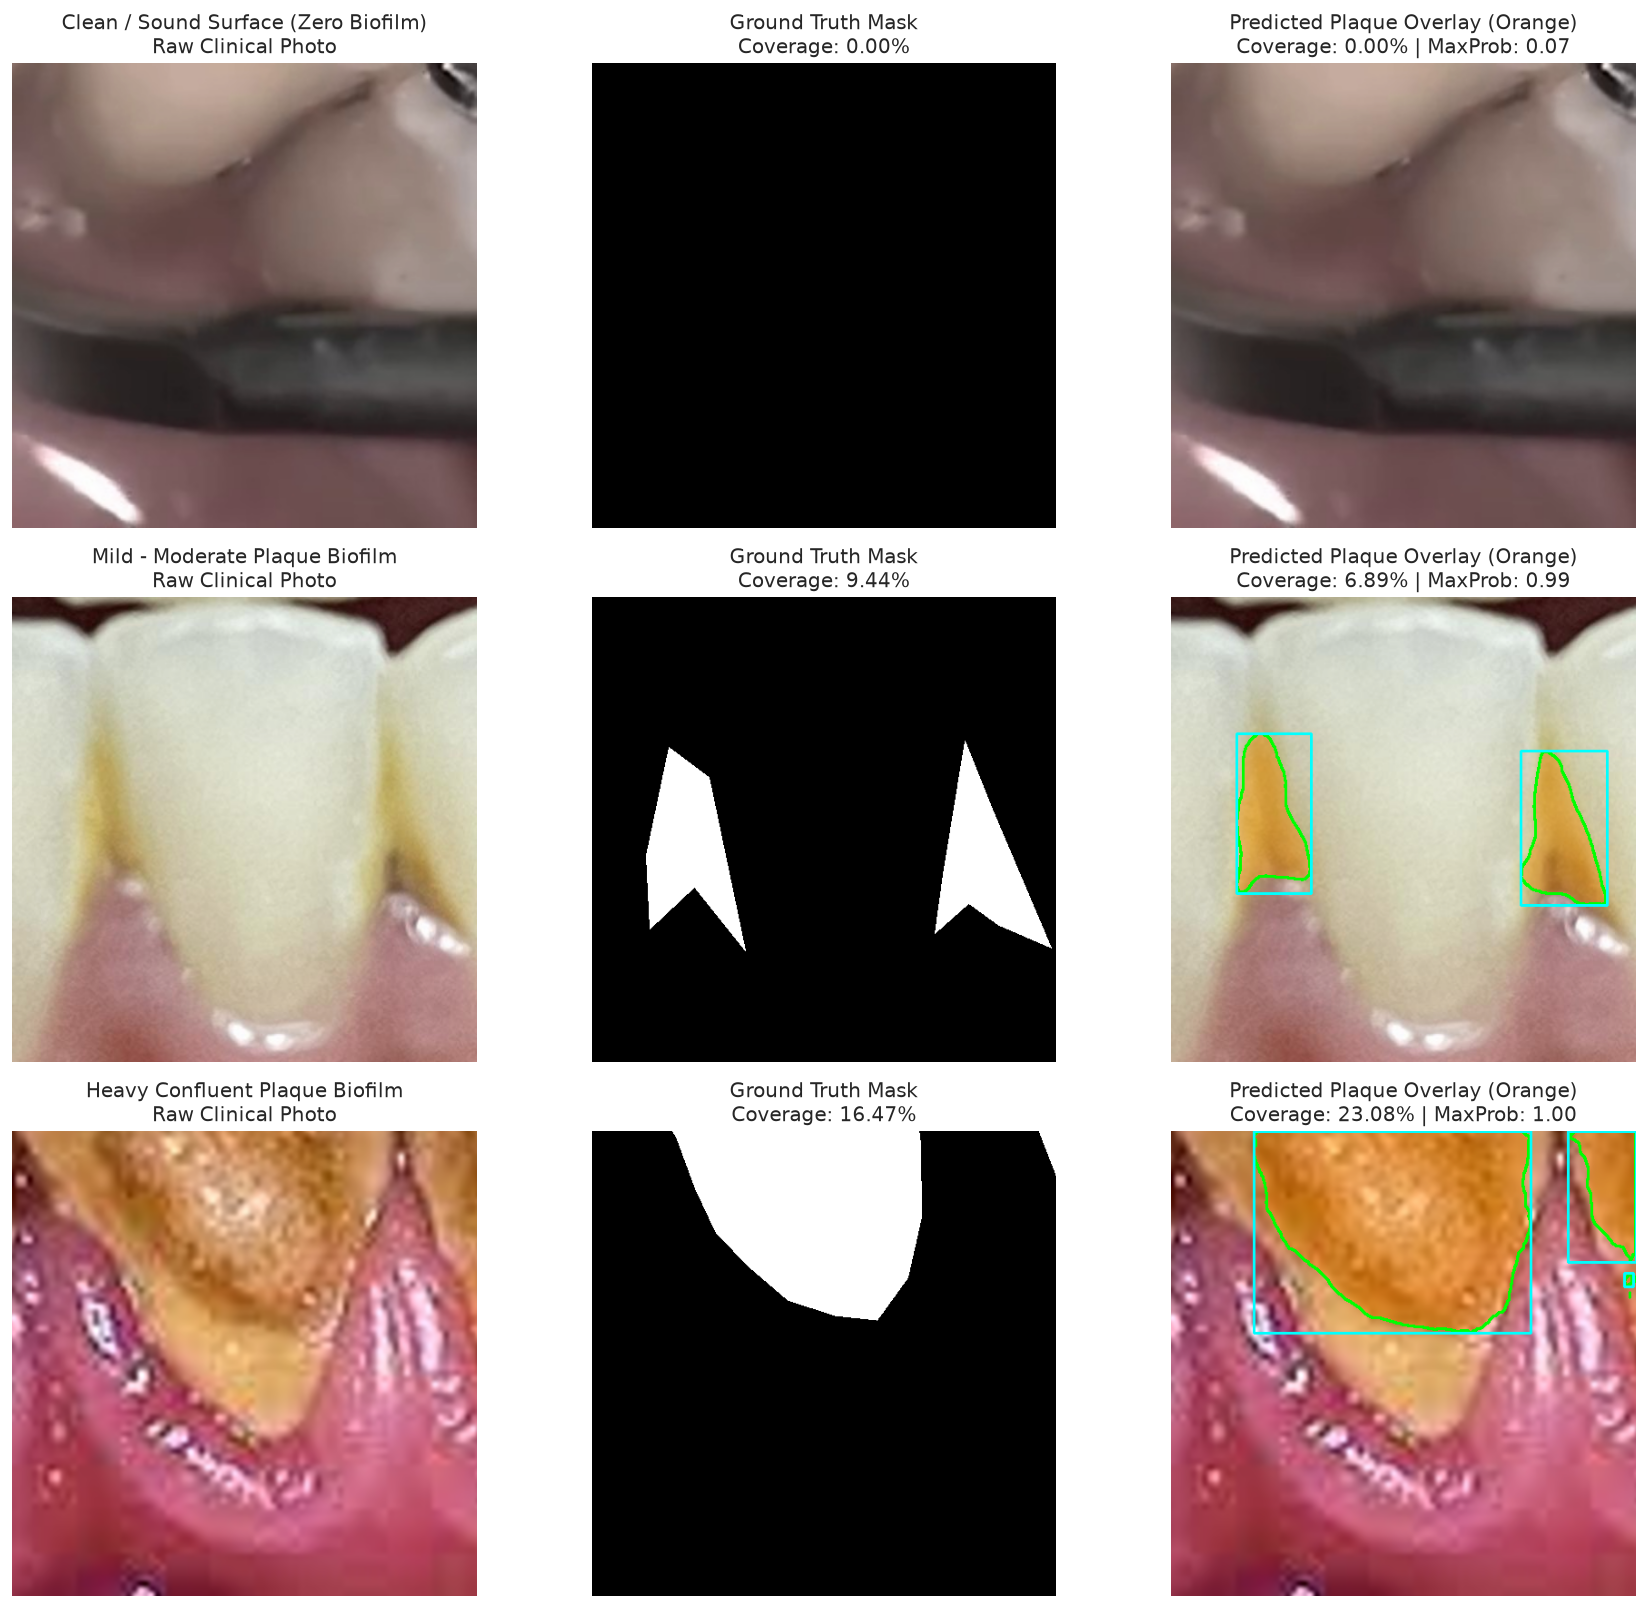

In [8]:
# ==============================================================================
# SECTION 8: Visual Plaque Diagnostic Overlays on Test Cases
# ==============================================================================

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

# Identify sample cases: clean, mild, confluent
clean_idx, mod_idx, heavy_idx = None, None, None
for idx in range(len(plaque_test_cached)):
    _, m = plaque_test_cached[idx]
    cov = np.sum(m) / (512 * 512)
    if clean_idx is None and cov == 0:
        clean_idx = idx
    elif mod_idx is None and 0.03 < cov < 0.10:
        mod_idx = idx
    elif heavy_idx is None and cov > 0.15:
        heavy_idx = idx
    if clean_idx is not None and mod_idx is not None and heavy_idx is not None:
        break

selected_plaque_cases = [
    ("Clean / Sound Surface (Zero Biofilm)", clean_idx if clean_idx is not None else 0),
    ("Mild - Moderate Plaque Biofilm", mod_idx if mod_idx is not None else 1),
    ("Heavy Confluent Plaque Biofilm", heavy_idx if heavy_idx is not None else 2)
]

fig, axes = plt.subplots(len(selected_plaque_cases), 3, figsize=(15, 4.5 * len(selected_plaque_cases)))

for row_i, (case_title, c_idx) in enumerate(selected_plaque_cases):
    img_t, msk_t = plaque_test_ds[c_idx]
    with torch.no_grad():
        out = plaque_model(img_t.unsqueeze(0).to(device))
        prob = torch.sigmoid(out).squeeze().cpu().numpy()
        pred = (prob >= 0.40).astype(np.uint8)

    img_np = img_t.permute(1, 2, 0).numpy()
    img_disp = np.clip((img_np * std + mean) * 255.0, 0, 255).astype(np.uint8)
    gt_disp = msk_t.squeeze().numpy().astype(np.uint8)

    # Diagnostic Overlay
    overlay = img_disp.copy()
    overlay[pred == 1] = [255, 140, 0]  # Amber/Orange for plaque
    blended = cv2.addWeighted(img_disp, 0.65, overlay, 0.35, 0)
    cnts, _ = cv2.findContours(pred, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(blended, cnts, -1, (0, 255, 0), 2)
    for c in cnts:
        if cv2.contourArea(c) >= 40:
            x, y, w, h = cv2.boundingRect(c)
            cv2.rectangle(blended, (x, y), (x + w, y + h), (0, 255, 255), 2)

    pred_area_pct = (np.sum(pred) / (512 * 512)) * 100.0
    gt_area_pct = (np.sum(gt_disp) / (512 * 512)) * 100.0

    axes[row_i, 0].imshow(img_disp)
    axes[row_i, 0].set_title(f"{case_title}\nRaw Clinical Photo")
    axes[row_i, 0].axis('off')

    axes[row_i, 1].imshow(gt_disp, cmap='gray')
    axes[row_i, 1].set_title(f"Ground Truth Mask\nCoverage: {gt_area_pct:.2f}%")
    axes[row_i, 1].axis('off')

    axes[row_i, 2].imshow(blended)
    axes[row_i, 2].set_title(f"Predicted Plaque Overlay (Orange)\nCoverage: {pred_area_pct:.2f}% | MaxProb: {np.max(prob):.2f}")
    axes[row_i, 2].axis('off')

plt.tight_layout()
plt.show()


---
## Section 9: Production Model Verification & Streamlit Integration

This section verifies that the trained checkpoint exists in `models/plaque_unet.pth` and is ready for real-time inference in the interactive Streamlit dashboard.

Launch the Streamlit dashboard:
```bash
.\.venv\Scripts\streamlit run app\app.py
```


In [9]:
# ==============================================================================
# SECTION 9: Production Model Verification & Export Confirmation
# ==============================================================================

print("=" * 80)
print("🎉 DENTAL PLAQUE SEGMENTATION UNET ARTIFACT VERIFICATION")
print("=" * 80)

if PLAQUE_MODEL_PATH.exists():
    size_mb = PLAQUE_MODEL_PATH.stat().st_size / (1024 * 1024)
    print(f"[✓] Plaque UNet Model Checkpoint : Verified")
    print(f"[*] Checkpoint Location           : {PLAQUE_MODEL_PATH.resolve()}")
    print(f"[*] Artifact File Size            : {size_mb:.2f} MB")
else:
    print(f"[!] Model checkpoint not found at {PLAQUE_MODEL_PATH}.")
    print("    Run Section 6 to train and export the checkpoint.")

print("\n[*] Streamlit Diagnostic App Launch Instruction:")
print("    .\\.venv\\Scripts\\streamlit run app\\app.py")
print("=" * 80)


🎉 DENTAL PLAQUE SEGMENTATION UNET ARTIFACT VERIFICATION
[✓] Plaque UNet Model Checkpoint : Verified
[*] Checkpoint Location           : D:\GItRepo\Automated Dental Caries and Plaque Detection from Intraoral Radiographs\models\plaque_unet.pth
[*] Artifact File Size            : 93.38 MB

[*] Streamlit Diagnostic App Launch Instruction:
    .\.venv\Scripts\streamlit run app\app.py
